# Loading the data

In [ ]:
import zipfile  
import os  
import tensorflow as tf  
from tensorflow.keras.utils import image_dataset_from_directory  


zip_path = 'archive.zip'  
extract_path = 'emotions_extract'  

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

IMG_SIZE = (48, 48)  
BATCH_SIZE = 64 
SEED = 42 

TRAIN_DIR = os.path.join(extract_path, 'train')
TEST_DIR = os.path.join(extract_path, 'test')

# Reading the data

In [ ]:
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,  
    color_mode='grayscale', 
    batch_size=BATCH_SIZE, 
    shuffle=True  
)
train_ds 

In [ ]:
class_names = train_ds.class_names
class_names 

In [ ]:
test_ds = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    shuffle=False 
)
test_ds 

In [ ]:
class_names = train_ds.class_names
print("Emotion Classes:", class_names)

# Split data

In [ ]:
# Create the TRAINING part: 80% of the images in the train folder.
train_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    subset='training', 
    validation_split=0.2, 
    seed=SEED,  
    shuffle=True
)
train_ds

In [ ]:
# Create the VALIDATION part: the other 20% of the train folder.
# It is used to check how the model performs on unseen data during training.
val_ds = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    subset='validation',  
    validation_split=0.2,  
    seed=SEED, 
    shuffle=True
)
val_ds

# Preprocessing

In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
normalization_layer

In [ ]:
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

# Model

In [ ]:
from tensorflow.keras import Sequential  
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Convolutional Neural Network (CNN) for classifying 48x48 grayscale face images
model = Sequential([
    # Block 1: 32 filters of size 3x3 scan the image to detect simple patterns (edges, lines).
    # ReLU keeps positive values only (adds non-linearity). input_shape = (height, width, 1 gray channel)
    Conv2D(32, (3, 3), activation='relu', input_shape=(48, 48, 1)),
    MaxPooling2D(2, 2),  # keeps the max of each 2x2 area -> halves the size, keeps the strongest features

    # Block 2: 64 filters detect more complex patterns (parts of a face: eyes, mouth)
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Block 3: 128 filters detect even higher-level shapes
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),  # turns the 2D feature maps into one long 1D vector for the dense layers
    Dense(128, activation='relu'),  # fully connected layer that combines all the detected features
    Dropout(0.5),  # randomly switches off 50% of neurons while training to reduce overfitting
    Dense(7, activation='softmax')  # output layer: 7 emotions, softmax gives a probability for each emotion
])

In [ ]:
model.compile(
    optimizer='adam',  
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']  
)

In [ ]:
model.summary()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping  # stops training when it stops improving
from sklearn.utils.class_weight import compute_class_weight  # computes weights to balance classes
import numpy as np

# Collect all the training labels into one list by looping over every batch
train_labels = []
for images, labels in train_ds:
    train_labels.extend(labels.numpy())  # convert the batch's label tensor to numpy and append
train_labels = np.array(train_labels)

# Some emotions have many more images than others (imbalanced data).
# 'balanced' gives higher weights to rare classes and lower weights to frequent ones.
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels), 
    y=train_labels)

# Convert to a dictionary {class_id: weight}, the format Keras expects.
# NOTE: this dictionary is created here but is not passed to model.fit() below (see the note in the fit cell).
class_weight_dict = dict(enumerate(class_weights))

In [1]:
from tensorflow.keras.callbacks import EarlyStopping
EPOCHS = 25  

# Stop training automatically if the validation loss has not improved for 5 epochs in a row.
early_stopping = EarlyStopping(
    monitor='val_loss',  # the metric to watch
    patience=5,  # how many epochs to wait without improvement before stopping
    restore_best_weights=True)  # go back to the weights from the best epoch

In [ ]:
history = model.fit(
    train_ds,  
    validation_data=val_ds,  
    epochs=EPOCHS,
    callbacks=[early_stopping])  

In [45]:
print("Final Training Accuracy:", history.history['accuracy'][-1])

Final Training Accuracy: 0.6553465723991394


113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step


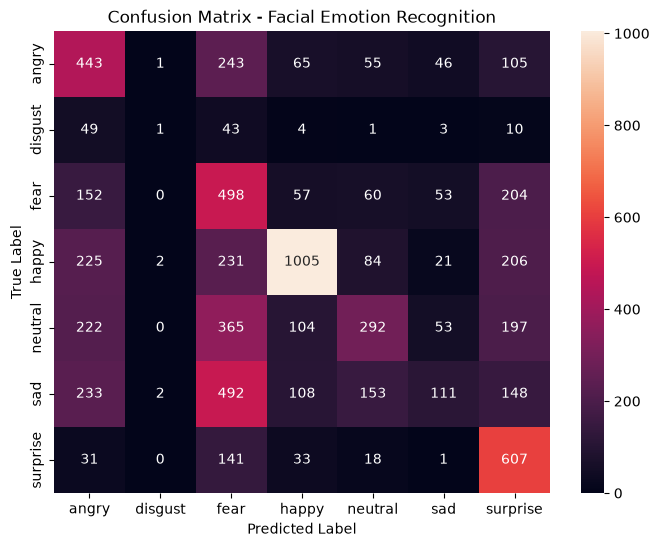

In [63]:
import numpy as np
from sklearn.metrics import confusion_matrix 

preds = np.argmax(model.predict(test_ds), axis=1)

true_labels = np.concatenate([y.numpy() for _, y in test_ds])

cm = confusion_matrix(true_labels, preds)

plt.figure(figsize=(8, 6)) 
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)  
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Facial Emotion Recognition')
plt.show()

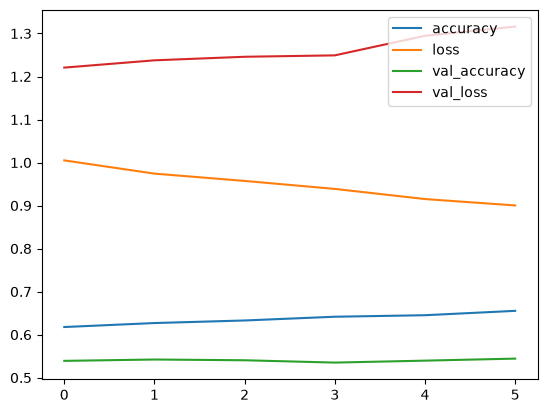

In [61]:
history_df = pd.DataFrame(history.history)
history_df.plot();  

In [57]:
test_loss, test_acc = model.evaluate(test_ds)

model.save('emotion_model.h5')

113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.4120 - loss: 113.1627
